# **GDRegressor**

In [105]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np

In [106]:
x,y = make_regression(n_samples=100,n_features=1,n_informative=1,n_targets=1,noise=20,random_state=42)

In [107]:
from sklearn.model_selection import train_test_split
x_train , x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

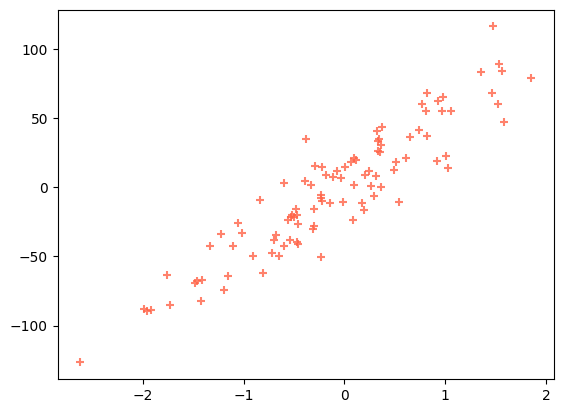

In [108]:
plt.scatter(x,y,marker='+',alpha=0.8,color = 'tomato')

In [109]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [110]:
reg.coef_,reg.intercept_

(array([46.747264]), np.float64(0.19844442845175525))

In [111]:
from sklearn.model_selection import cross_val_score
np.mean(cross_val_score(reg,x,y,scoring='r2',cv=10))

np.float64(0.8016058585014069)

In [112]:
y_pred =  reg.predict(x_test)
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)*100

80.19015156159199

In [113]:
class GDRegressor:
    def __init__(self,lr,epoces):
        self.b = -120
        self.m = 100
        self.epoces = epoces
        self.lr = lr
    def fit(self,x_train,y_train):
        self.x_train = x_train
        self.y_train = y_train
        
        for _ in range(self.epoces):
            # calculate the b using GD
            loss_slope_b = -2 * np.sum(y_train - self.m*x_train.ravel() - self.b)
            loss_slope_m = -2 * np.sum((y_train - self.m*x_train.ravel() - self.b)*x_train.ravel())
            self.b = self.b - (self.lr*loss_slope_b)
            self.m = self.m - (self.lr*loss_slope_m)
        print(self.m,self.b)
    def predict(self,X):
        return self.m *X + self.b    

In [114]:
gd = GDRegressor(lr=0.001,epoces=100)
gd.fit(x_train,y_train)

46.74724384261902 0.19843239298069928


In [115]:
y_pred =  gd.predict(x_test)
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)*100

80.19013865854268

In [116]:
import pandas as pd

In [117]:
pd.DataFrame({"X":x_test.ravel(),"Y":y_test.ravel(),"Y'":gd.predict(x_test).ravel()})

,X,Y,Y'
0,-1.328186,-42.458212,-61.890605
1,1.477894,116.377367,69.285906
2,0.812526,54.902670,38.181775
3,-0.392108,4.544398,-18.131543
4,-0.234153,-5.475043,-10.747593
5,-0.291694,15.670897,-13.437446
6,-0.465730,-39.291796,-21.573150
7,-1.763040,-63.062273,-82.218836
8,0.821903,37.224352,38.620109
9,0.931280,62.687202,43.733211
